In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

file_path = "ride_booking_cleaned.csv"

print("Current working directory:", os.getcwd())
print("File exists:", os.path.exists(file_path))

Current working directory: C:\Users\SASWAT
File exists: True


In [3]:
df = pd.read_csv("ride_booking_cleaned.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 150000
Columns: 23


,date,month_name,time,booking_id,booking_status,customer_id,vehicle_type,pickup_location,drop_location,avg_vtat,...,cancelled_rides_by_driver,driver_cancellation_reason,incomplete_rides,incomplete_rides_reason,booking_value,ride_distance,driver_ratings,customer_rating,payment_method,booking_hour
0,2024-03-23,March,12:29:38,CNR5884300,No Driver Found,CID1982111,eBike,Palam Vihar,Jhilmil,0.0,...,0,NaN,0,NaN,0,0.00,0.0,0.0,NaN,12
1,2024-11-29,November,18:01:39,CNR1326809,Incomplete,CID4604802,Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,...,0,NaN,1,Vehicle Breakdown,237,5.73,0.0,0.0,UPI,18
2,2024-08-23,August,08:56:10,CNR8494506,Completed,CID9202816,Auto,Khandsa,Malviya Nagar,13.4,...,0,NaN,0,NaN,627,13.58,4.9,4.9,Debit Card,8
3,2024-10-21,October,17:17:25,CNR8906825,Completed,CID2610914,Premier Sedan,Central Secretariat,Inderlok,13.1,...,0,NaN,0,NaN,416,34.02,4.6,5.0,UPI,17
4,2024-09-16,September,22:08:00,CNR1950162,Completed,CID9933542,Bike,Ghitorni Village,Khan Market,5.3,...,0,NaN,0,NaN,737,48.21,4.1,4.3,UPI,22


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (150000, 23)

Column names:
['date', 'month_name', 'time', 'booking_id', 'booking_status', 'customer_id', 'vehicle_type', 'pickup_location', 'drop_location', 'avg_vtat', 'avg_ctat', 'cancelled_rides_by_customer', 'reason_for_cancelling_by_customer', 'cancelled_rides_by_driver', 'driver_cancellation_reason', 'incomplete_rides', 'incomplete_rides_reason', 'booking_value', 'ride_distance', 'driver_ratings', 'customer_rating', 'payment_method', 'booking_hour']

Data types:
date                                     str
month_name                               str
time                                     str
booking_id                               str
booking_status                           str
customer_id                              str
vehicle_type                             str
pickup_location                          str
drop_location                            str
avg_vtat                             float64
avg_ctat                             float64
cancelled_rides_

,missing_count
incomplete_rides_reason,141000
reason_for_cancelling_by_customer,139500
driver_cancellation_reason,123000
payment_method,48000
date,0
month_name,0
time,0
vehicle_type,0
customer_id,0
booking_status,0



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,150000,365,2024-11-16,462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month_name,150000,12,July,12897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,150000,62910,17:44:57,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_id,150000,148767,CNR7908610,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_status,150000,5,Completed,93000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,150000,148788,CID6468528,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,150000,7,Auto,37419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_location,150000,176,Khandsa,949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drop_location,150000,176,Ashram,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_vtat,150000.0,NaN,NaN,NaN,7.864407,4.23064,0.0,4.7,7.8,11.0,20.0


In [5]:
status_summary = (
    df["booking_status"]
    .value_counts()
    .rename_axis("booking_status")
    .reset_index(name="total_bookings")
)

status_summary["percentage"] = (
    status_summary["total_bookings"] / len(df) * 100
).round(2)

display(status_summary)

,booking_status,total_bookings,percentage
0,Completed,93000,62.0
1,Cancelled by Driver,27000,18.0
2,No Driver Found,10500,7.0
3,Cancelled by Customer,10500,7.0
4,Incomplete,9000,6.0


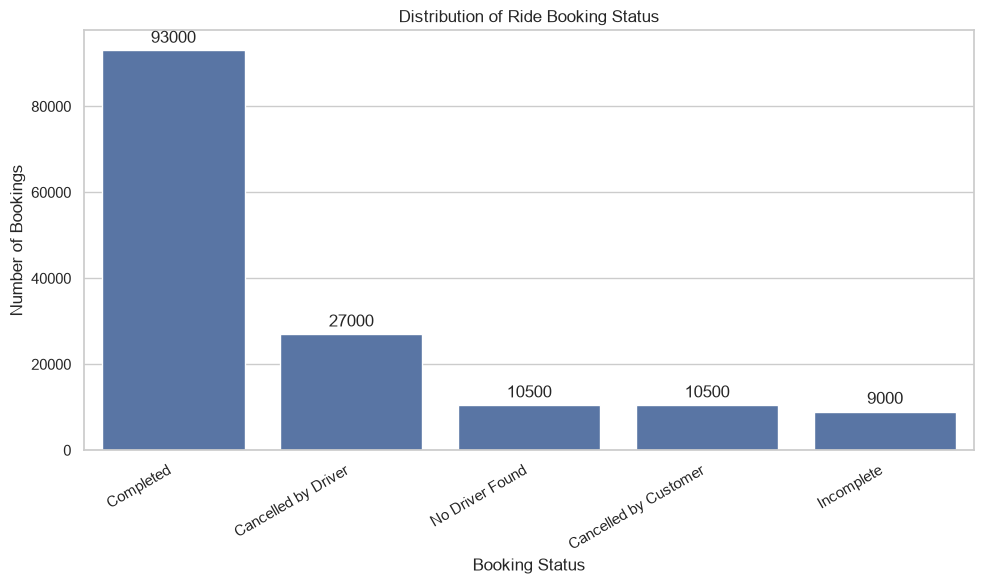

In [6]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=status_summary,
    x="booking_status",
    y="total_bookings"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Distribution of Ride Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

The company should investigate the reasons behind unsuccessful bookings. However, the status distribution alone does not establish why they occurred.

Analyze customer cancellation reasons

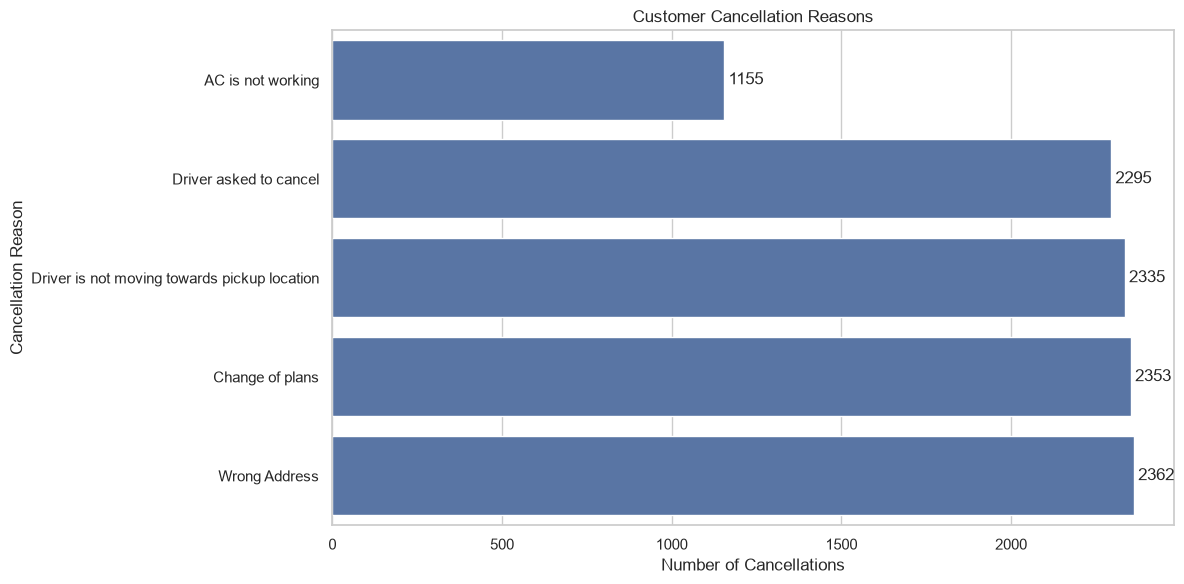

,cancellation_reason,total_cancellations,percentage
4,AC is not working,1155,11.00
3,Driver asked to cancel,2295,21.86
2,Driver is not moving towards pickup location,2335,22.24
1,Change of plans,2353,22.41
0,Wrong Address,2362,22.50


In [7]:
customer_cancel_summary = (
    df.loc[
        df["booking_status"] == "Cancelled by Customer",
        "reason_for_cancelling_by_customer"
    ]
    .value_counts()
    .rename_axis("cancellation_reason")
    .reset_index(name="total_cancellations")
)

customer_cancel_summary["percentage"] = (
    customer_cancel_summary["total_cancellations"]
    / customer_cancel_summary["total_cancellations"].sum()
    * 100
).round(2)

customer_cancel_summary = customer_cancel_summary.sort_values(
    "total_cancellations",
    ascending=True
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=customer_cancel_summary,
    x="total_cancellations",
    y="cancellation_reason"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Customer Cancellation Reasons")
plt.xlabel("Number of Cancellations")
plt.ylabel("Cancellation Reason")
plt.tight_layout()
plt.show()

display(customer_cancel_summary)

Analyze driver cancellation reasons

In [8]:
driver_cancel_summary = (
    df.loc[
        df["booking_status"] == "Cancelled by Driver",
        "driver_cancellation_reason"
    ]
    .value_counts()
    .rename_axis("cancellation_reason")
    .reset_index(name="total_cancellations")
)

driver_cancel_summary["percentage"] = (
    driver_cancel_summary["total_cancellations"]
    / driver_cancel_summary["total_cancellations"].sum()
    * 100
).round(2)

display(driver_cancel_summary)

,cancellation_reason,total_cancellations,percentage
0,Customer related issue,6837,25.32
1,The customer was coughing/sick,6751,25.00
2,Personal & Car related issues,6726,24.91
3,More than permitted people in there,6686,24.76


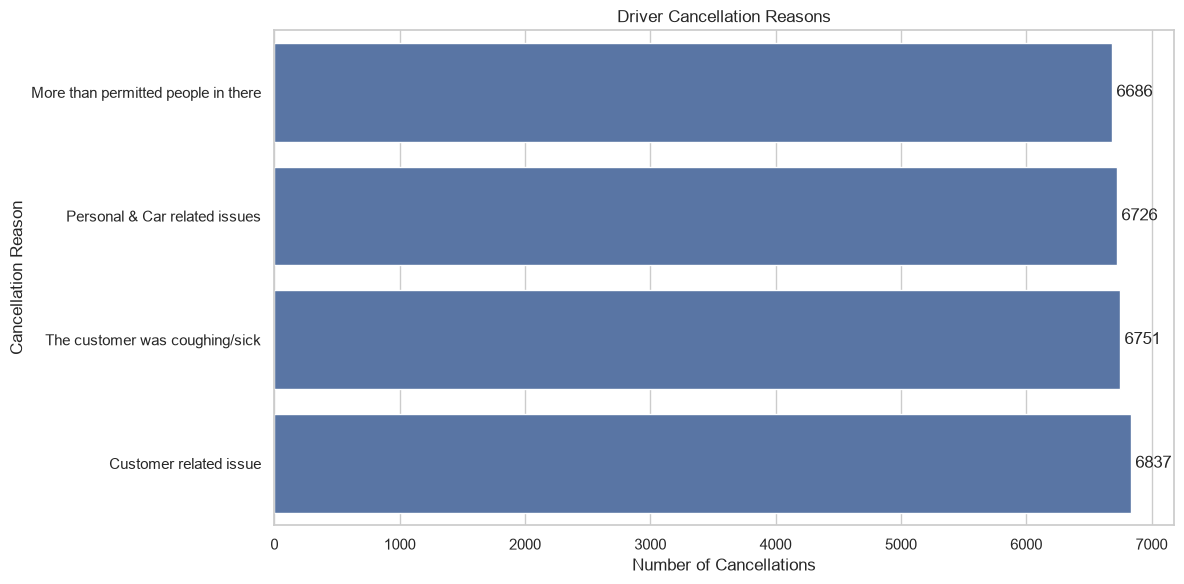

In [9]:
driver_cancel_plot = driver_cancel_summary.sort_values(
    "total_cancellations",
    ascending=True
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=driver_cancel_plot,
    x="total_cancellations",
    y="cancellation_reason"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Driver Cancellation Reasons")
plt.xlabel("Number of Cancellations")
plt.ylabel("Cancellation Reason")
plt.tight_layout()
plt.show()

Analyze bookings by hour

Business question: During which hours are bookings most common?

,booking_hour,total_bookings
0,0,1373
1,1,1360
2,2,1339
3,3,1383
4,4,1321
5,5,2786
6,6,4160
7,7,5450
8,8,6861
9,9,8234


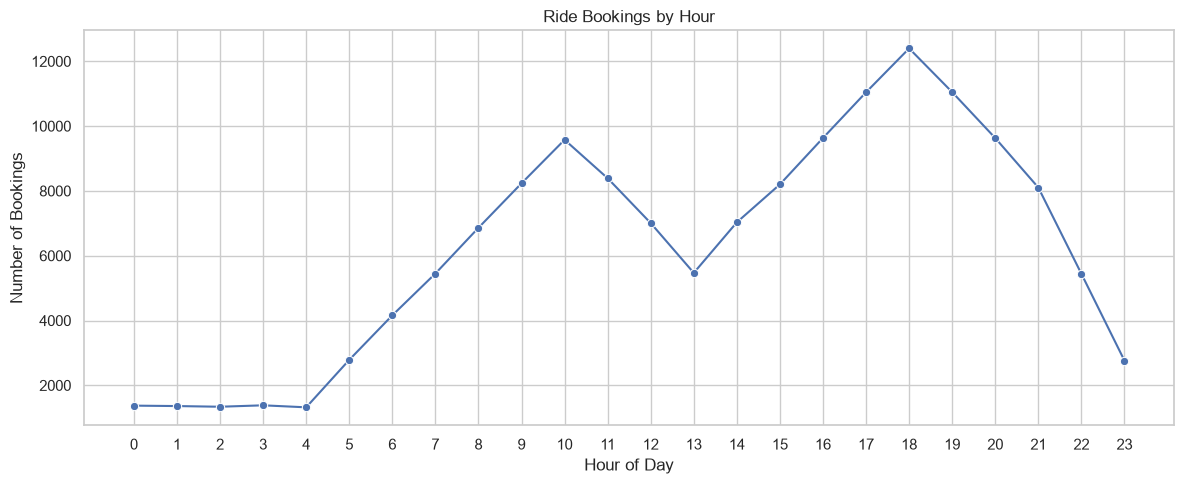

In [10]:
hourly_bookings = (
    df.groupby("booking_hour")
      .size()
      .reset_index(name="total_bookings")
      .sort_values("booking_hour")
)

display(hourly_bookings)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_bookings,
    x="booking_hour",
    y="total_bookings",
    marker="o"
)

plt.title("Ride Bookings by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Bookings")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

Compare booking outcomes by hour

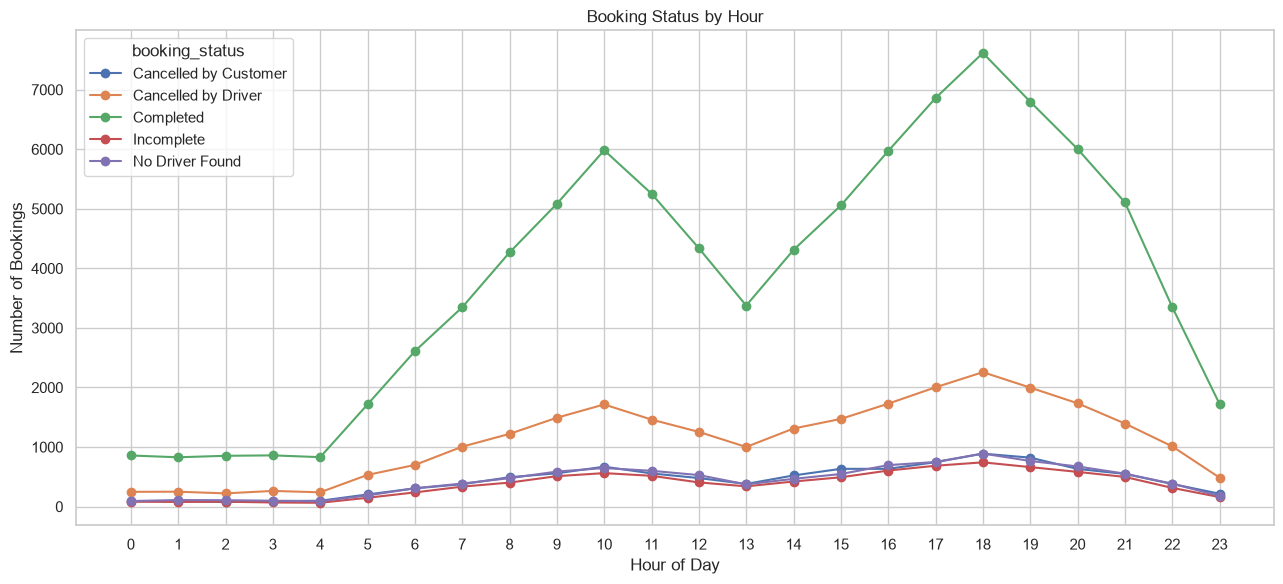

In [11]:
hourly_status = pd.crosstab(
    df["booking_hour"],
    df["booking_status"]
)

hourly_status.plot(
    kind="line",
    figsize=(13, 6),
    marker="o"
)

plt.title("Booking Status by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Bookings")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

Compare booking outcomes by vehicle type

Business question: Does booking status vary by vehicle type?

booking_status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
vehicle_type,,,,,
Auto,2680,6643,23155,2260,2681
Bike,1575,4077,14034,1328,1503
Go Mini,2097,5330,18549,1815,2015
Go Sedan,1832,5031,16676,1642,1960
Premier Sedan,1266,3250,11252,1063,1280
Uber XL,327,762,2783,262,315
eBike,723,1907,6551,630,746


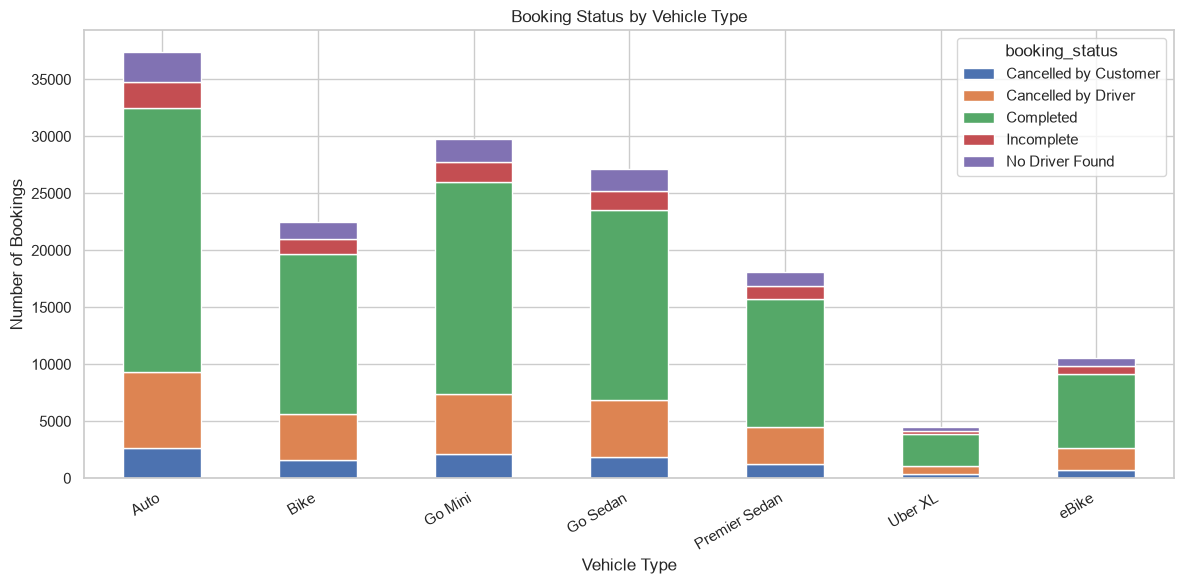

In [12]:
vehicle_status = pd.crosstab(
    df["vehicle_type"],
    df["booking_status"]
)

display(vehicle_status)

vehicle_status.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Booking Status by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

booking_status,Cancelled by Customer,Cancelled by Driver,Completed,Incomplete,No Driver Found
vehicle_type,,,,,
Auto,7.16,17.75,61.88,6.04,7.16
Bike,6.99,18.11,62.33,5.90,6.67
Go Mini,7.04,17.88,62.23,6.09,6.76
Go Sedan,6.75,18.54,61.44,6.05,7.22
Premier Sedan,6.99,17.94,62.13,5.87,7.07
Uber XL,7.35,17.13,62.55,5.89,7.08
eBike,6.85,18.06,62.05,5.97,7.07


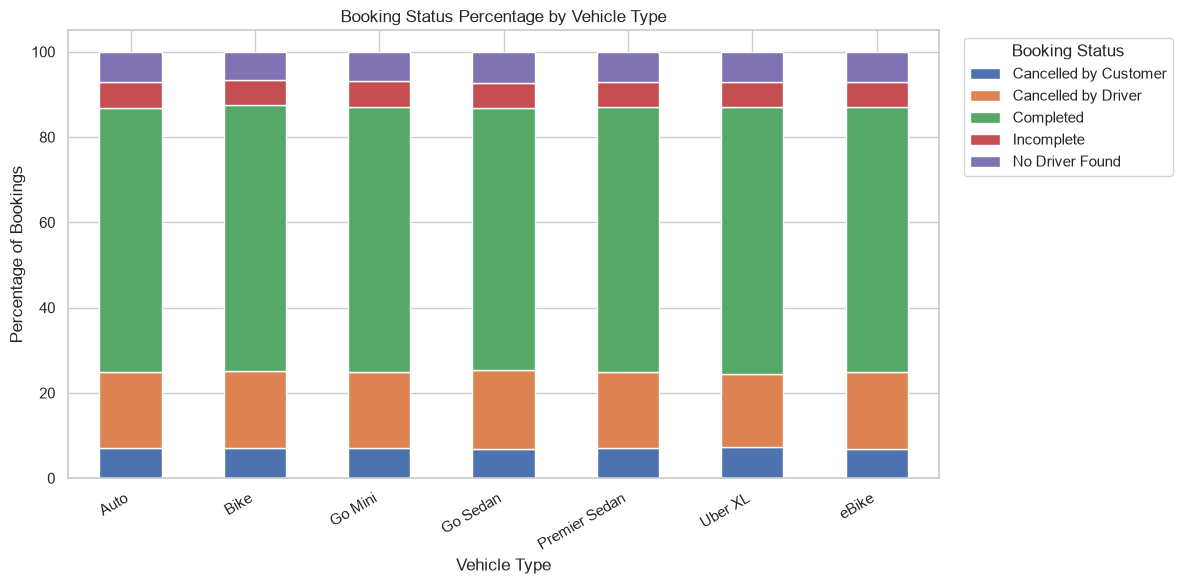

In [13]:
vehicle_status_percentage = pd.crosstab(
    df["vehicle_type"],
    df["booking_status"],
    normalize="index"
).mul(100).round(2)

display(vehicle_status_percentage)

vehicle_status_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Booking Status Percentage by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Percentage of Bookings")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Booking Status", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Analyze pickup locations

Business question: Which pickup locations receive the most bookings?

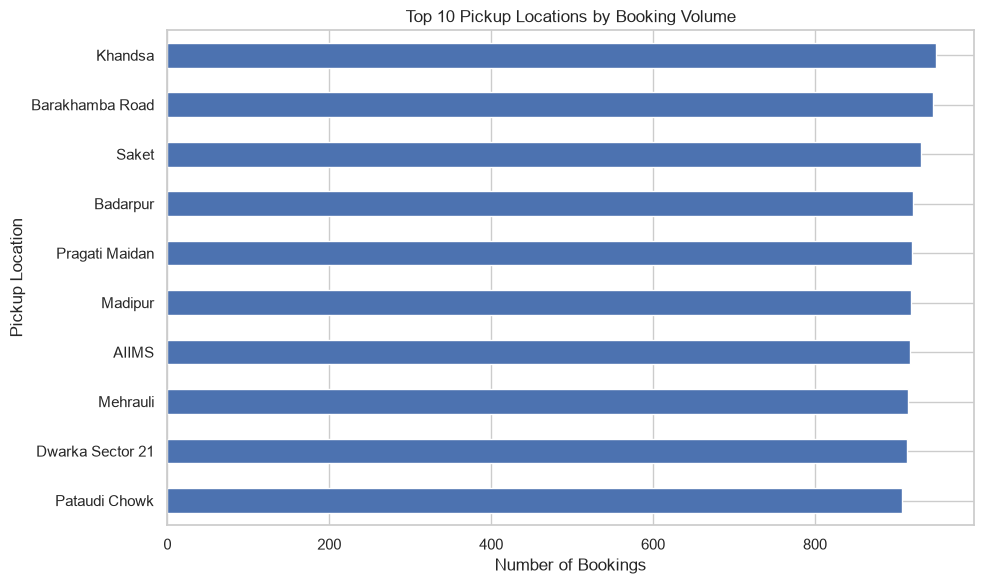

In [14]:
top_pickup_locations = (
    df["pickup_location"]
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

top_pickup_locations.plot(kind="barh")

plt.title("Top 10 Pickup Locations by Booking Volume")
plt.xlabel("Number of Bookings")
plt.ylabel("Pickup Location")
plt.tight_layout()
plt.show()

Investigate cancellation rates by pickup location

In [15]:
location_analysis = df.copy()

location_analysis["is_cancelled"] = (
    location_analysis["booking_status"].isin([
        "Cancelled by Customer",
        "Cancelled by Driver"
    ])
)

pickup_summary = (
    location_analysis.groupby("pickup_location")
    .agg(
        total_bookings=("booking_status", "size"),
        cancelled_bookings=("is_cancelled", "sum")
    )
)

pickup_summary["cancellation_rate"] = (
    pickup_summary["cancelled_bookings"]
    / pickup_summary["total_bookings"] * 100
).round(2)

# Avoid drawing conclusions from locations with very few bookings.
pickup_summary = pickup_summary[
    pickup_summary["total_bookings"] >= 100
]

display(
    pickup_summary.sort_values(
        "cancellation_rate",
        ascending=False
    ).head(10)
)

,total_bookings,cancelled_bookings,cancellation_rate
pickup_location,,,
Vinobapuri,823,244,29.65
Akshardham,839,248,29.56
Munirka,815,232,28.47
Qutub Minar,823,233,28.31
Kadarpur,844,238,28.20
Faridabad Sector 15,831,233,28.04
GTB Nagar,872,242,27.75
Shahdara,820,227,27.68
Nehru Place,885,244,27.57


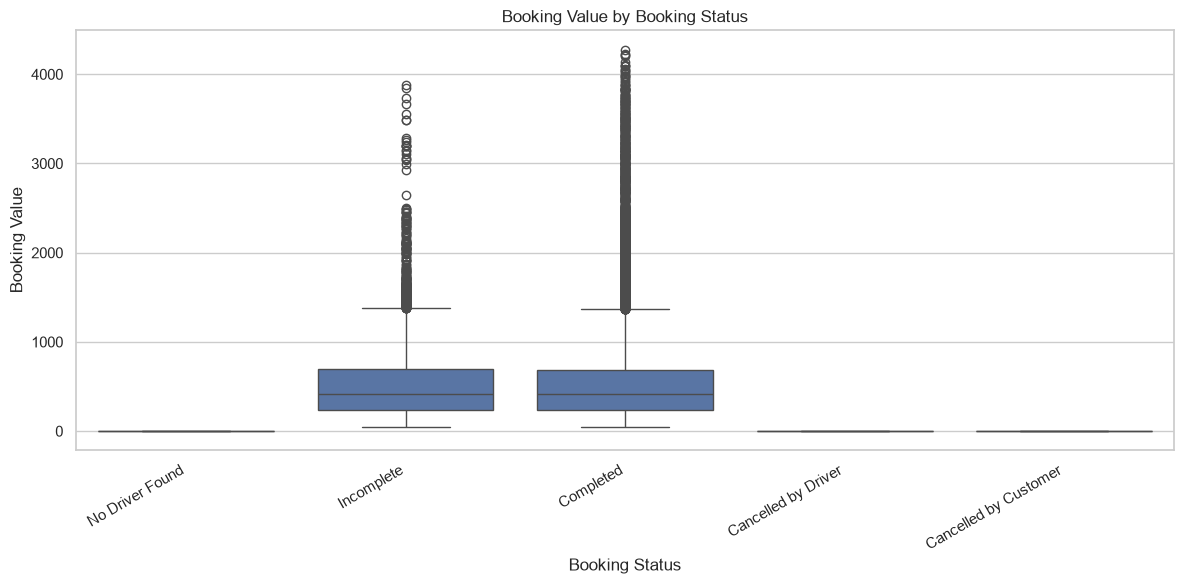

In [16]:
##Booking value by status
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="booking_status",
    y="booking_value"
)

plt.title("Booking Value by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Booking Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

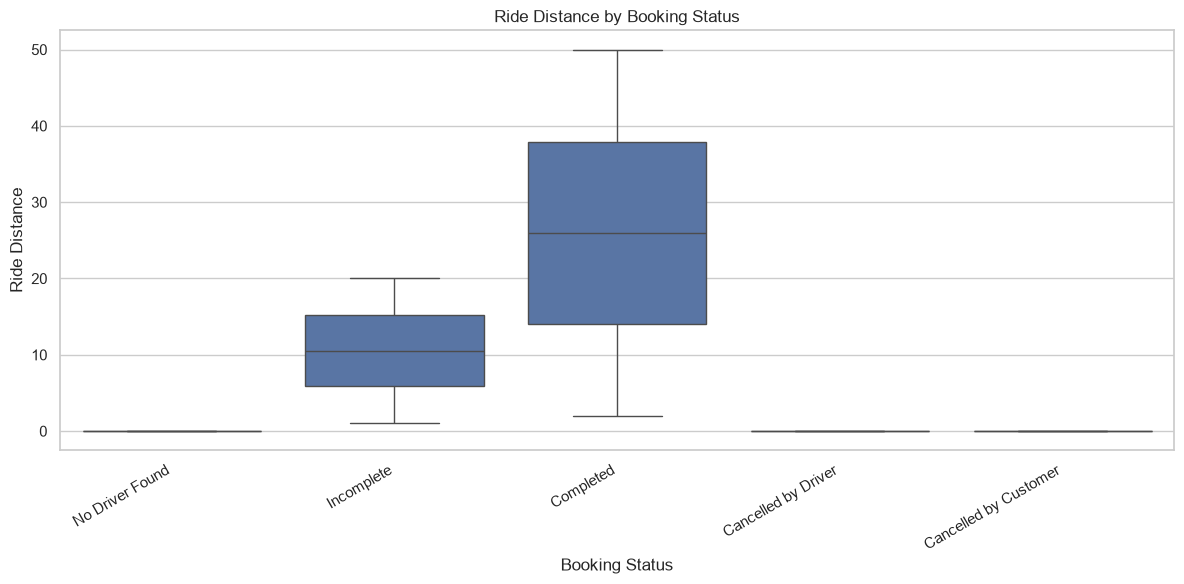

In [17]:
##Ride distance by status
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="booking_status",
    y="ride_distance"
)

plt.title("Ride Distance by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Ride Distance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

##Analyze booking trends over time

Business question: How does booking volume change month by month?

,date,total_bookings
0,2024-01-01,12861
1,2024-02-01,11927
2,2024-03-01,12719
3,2024-04-01,12199
4,2024-05-01,12778
5,2024-06-01,12440
6,2024-07-01,12897
7,2024-08-01,12636
8,2024-09-01,12248
9,2024-10-01,12651


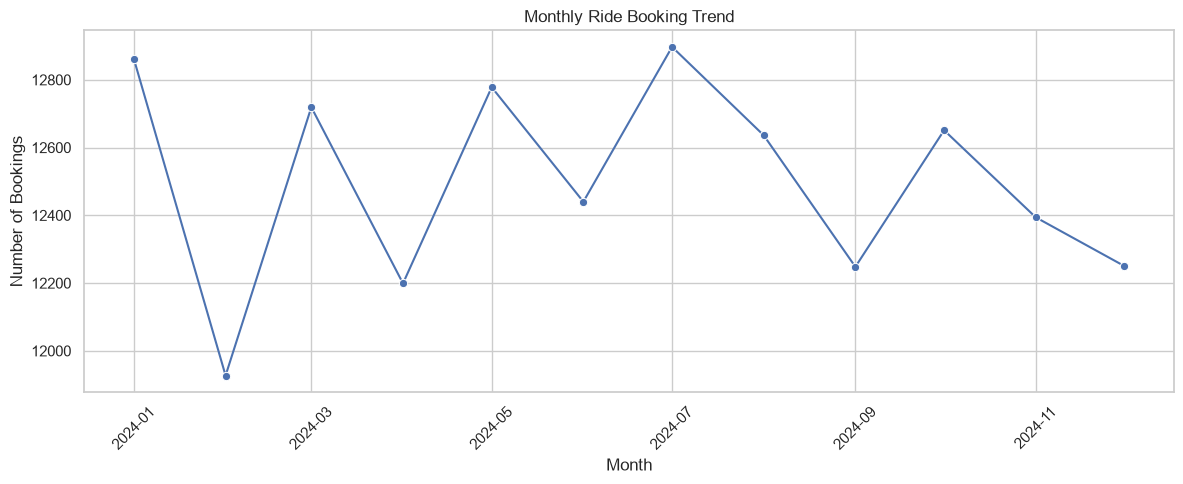

In [18]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

monthly_bookings = (
    df.set_index("date")
      .resample("MS")
      .size()
      .reset_index(name="total_bookings")
)

display(monthly_bookings)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_bookings,
    x="date",
    y="total_bookings",
    marker="o"
)

plt.title("Monthly Ride Booking Trend")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key Business Insights

1. **Booking Success Rate:** 93,000 bookings (62%) were completed, while 57,000 bookings (38%) were unsuccessful or not completed.

2. **Booking Status:** Driver cancellations accounted for 18% of all bookings, followed by customer cancellations (7%), bookings with no driver found (7%), and incomplete rides (6%).

3. **Customer Cancellation Reasons:** Wrong address was the most frequent reason (22.50%), followed by change of plans (22.41%) and the driver not moving towards the pickup location (22.24%).

4. **Driver Cancellation Reasons:** Customer-related issues represented 25.32% of driver cancellations, followed by the customer being sick (25.00%) and personal or car-related issues (24.91%).

5. **Peak Booking Hours:** Booking demand peaked at 6 PM, with 12,397 bookings. The lowest demand occurred at 4 AM, with 1,321 bookings.

6. **Vehicle Performance:** Completion rates were similar across vehicle types, ranging from approximately 61.44% to 62.55%. Go Sedan had the lowest completion rate, while Uber XL had the highest.

7. **Pickup Location Analysis:** Among locations with at least 100 bookings, Vinobapuri had the highest cancellation rate at 29.65%, followed closely by Akshardham at 29.56%. These locations may require further investigation.

8. **Monthly Booking Trends:** July recorded the highest number of bookings (12,897), while February recorded the lowest (11,927).

## Business Recommendations

* Investigate the main reasons for driver cancellations and identify opportunities to improve driver reliability.
* Improve pickup-location accuracy and communication to reduce address-related cancellations.
* Review driver availability during peak hours, especially around 5 PM–7 PM.
* Investigate locations with high cancellation rates to identify possible operational issues.
* Monitor monthly booking trends to support demand planning and resource allocation.

## Conclusion

The analysis shows that although 62% of bookings were completed, 38% were unsuccessful or not completed. Driver cancellations, pickup-related issues, and demand patterns are important areas for further investigation.

**Next Step:** Build a machine learning classification model to predict booking status using information available when a booking is created.
